# **Nama: Andika Dinata**
# **NIM: 123140096**

In [19]:
# Memuat library yang dibutuhkan dalam pemrosesan data dan pembuatan
# model dengan menggunakan K-Means dan Agglomerative clustering.
import matplotlib.pyplot as plt
import pandas as pd
import os
import seaborn as sns
from sklearn import preprocessing
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.cluster import KMeans, AgglomerativeClustering

In [20]:
# Import library yang digunakan untuk menghubungkan dengan google drive
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. **Data Loading and Preparation**

In [21]:
# Memuat dataset yang langsung dihubungkan ke kaggle dengan membuat penghubung (link)
# antara google colab dan Kaggle.
#
# Langkah-langkahnya adalah:
# 1. login ke Kaggle dan masuk ke menu Your API Token (dengan klik tombol profile akun di
#    pojok kanan atas). Selanjutnya ambil Token melalui
#    Create Legacy API Key
# 2. Setelah diunduh file kaggle.json maka diunggah ke google drive
#    (misal pada path: My Drive/kaggle.json)
# 3. Melakukan instalasi Library Kaggle
! pip install kaggle
# 4. Membuat direktori dengan nama '.kaggle'
! mkdir ~/.kaggle
# 5. Melakukan copy file 'kaggle.json' ke dalam direktori yang baru tersebut
! cp '/content/drive/MyDrive/kaggle.json' ~/.kaggle/
# 6. Memberikan izin akses untuk file tersebut
! chmod 600 ~/.kaggle/kaggle.json
# 7. Download Customer Segmentation Dataset dari Kaggle
! kaggle datasets download vjchoudhary7/customer-segmentation-tutorial-in-python
! unzip customer-segmentation-tutorial-in-python.zip

mkdir: cannot create directory ‘/root/.kaggle’: File exists
cp: cannot stat '/content/drive/MyDrive/kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python
License(s): other
customer-segmentation-tutorial-in-python.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  customer-segmentation-tutorial-in-python.zip
replace Mall_Customers.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: Mall_Customers.csv      


In [22]:
# Load data ketika file .csv telah tersimpan pada google drive
path_file = "/content/Mall_Customers.csv"
dataset = pd.read_csv(path_file, header=0, sep=',')
dataset

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


Penjelasan:

CSV dibaca ke DataFrame

In [23]:
# Mengetahui data type setiap kolom yang berhasil termuat
dataset.dtypes

,0
CustomerID,int64
Gender,object
Age,int64
Annual Income (k$),int64
Spending Score (1-100),int64


In [24]:
# Melakukan konversi untuk semua data object ke numerik agar bisa masuk ke tensor
dist_column = dataset['Gender'].unique()
dataset['Gender'].replace(dist_column,list(range(len(dist_column))), inplace=True)
dataset

/tmp/ipykernel_433/3836737172.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  dataset['Gender'].replace(dist_column,list(range(len(dist_column))), inplace=True)
/tmp/ipykernel_433/3836737172.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dataset['Gender'].replace(dist_column,list(range(len(

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,0,19,15,39
1,2,0,21,15,81
2,3,1,20,16,6
3,4,1,23,16,77
4,5,1,31,17,40
...,...,...,...,...,...
195,196,1,35,120,79
196,197,1,45,126,28
197,198,0,32,126,74
198,199,0,32,137,18


Penjelasan:

Gender diubah menjadi nilai biner

In [25]:
# Pemisahan fitur yang akan dipertimbangkan dan menampilkan ukuran dari dataset
X = dataset.iloc[:,1:5]
print(f"Data X = {X.shape}")

Data X = (200, 4)


Penjelasan:

Kolom CustomerID dibuang karena cuma identitas

In [26]:
# Melakukan normalisasi data ke dalam rentang nilai data yang seragam
min_max_scaler = preprocessing.MinMaxScaler()
X = min_max_scaler.fit_transform(X.values.reshape(-1, X.shape[1]))
X = pd.DataFrame(X)
print(f"Contoh data X setelah normalisasi \n{X.head()}")

Contoh data X setelah normalisasi 
     0         1         2         3
0  0.0  0.019231  0.000000  0.387755
1  0.0  0.057692  0.000000  0.816327
2  1.0  0.038462  0.008197  0.051020
3  1.0  0.096154  0.008197  0.775510
4  1.0  0.250000  0.016393  0.397959


Penjelasan:

MinMaxScaler membuat tiap kolom berada di rentang 0 sampai 1, supaya fitur
berskala besar seperti income tidak mendominasi perhitungan jarak.

In [27]:
# Menerapkan PCA dengan principal component sebanyak 3 untuk kebutuhan visualisasi
pca = PCA(n_components = 3)
data_pca = pca.fit_transform(X)
data_pca = pd.DataFrame(data_pca,columns=['PC1','PC2','PC3'])
data_pca.head()

,PC1,PC2,PC3
0,-0.532955,-0.227841,-0.321860
1,-0.513939,-0.493080,0.016202
2,0.446266,0.087079,-0.555761
3,0.478796,-0.366617,0.010714
4,0.451984,0.003006,-0.159208


Penjelasan:

PCA meringkas 4 fitur menjadi 3 komponen supaya bisa digambar dalam 3D.

PCA hanya dipakai untuk visualisasi, proses clustering tetap memakai X dengan 4 fitur.

## **2. Clustering dengan K-Means dan Silhouette Score**

Hasil Pencarian Nilai K Terbaik :



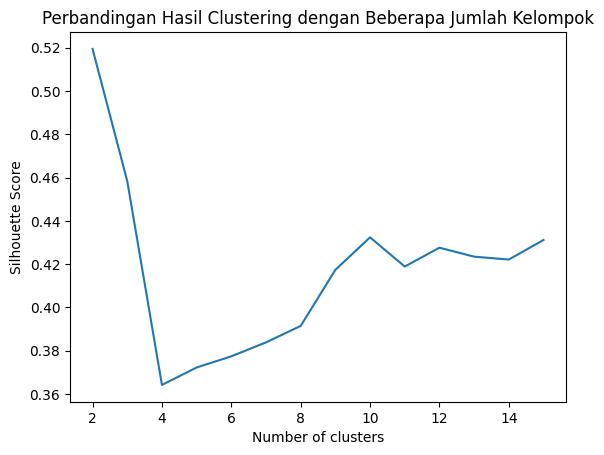

In [28]:
# Proses clustering dengan menggunakan K-Means yang mempertimbangkan beberapa
# nilai/jumlah kelompok
list_silhouetteScore = []
for i in range(2, 16):
  kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=0)
  kmeans.fit(X)
  list_silhouetteScore.append(silhouette_score(X, kmeans.fit_predict(X)))
print ("Hasil Pencarian Nilai K Terbaik :\n")
plt.plot(range(2, 16), list_silhouetteScore)
plt.title('Perbandingan Hasil Clustering dengan Beberapa Jumlah Kelompok')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.show()

Penjelasan:

K-Means dilatih untuk k = 2 sampai 15, lalu silhouette score tiap k dicatat
dan diplot.

Hasilnya skor tertinggi ada di k=2 (sekitar 0.52), turun ke sekitar 0.36 di k=4, lalu naik lagi ke 0.42 sampai 0.43 pada k=10 sampai 15, tapi tidak melewati k=2.

In [29]:
# Penggunaan model clustering dengan nilai cluster yang dianggap terbaik
kmeans = KMeans(n_clusters=2, init='k-means++', max_iter=300, n_init=10, random_state=0)
kmeans.fit(X)
print(kmeans.fit_predict(X))

[0 0 1 1 1 1 1 1 0 1 0 1 1 1 0 0 1 0 0 1 0 0 1 0 1 0 1 0 1 1 0 1 0 0 1 1 1
 1 1 1 1 0 0 1 1 1 1 1 1 1 1 0 1 0 1 0 1 0 1 0 0 0 1 1 0 0 1 1 0 1 0 1 1 1
 0 0 1 0 1 1 0 0 0 1 1 0 1 1 1 1 1 0 0 1 1 0 1 1 0 0 1 1 0 0 0 1 1 0 0 0 0
 1 1 0 1 1 1 1 1 1 0 1 1 0 1 1 0 0 0 0 0 0 1 1 0 1 1 0 0 1 1 0 1 1 0 0 0 1
 1 0 0 0 1 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 1 0 0 0 0 0 1 1 0 0 0 0 1 1 0 1 1
 0 1 0 1 1 1 1 0 1 1 1 1 0 0 0]


Penjelasan:

Dipilih k=2 karena silhouette-nya paling tinggi.
Outputnya array berisi label cluster (0 atau 1) untuk 200 pelanggan.

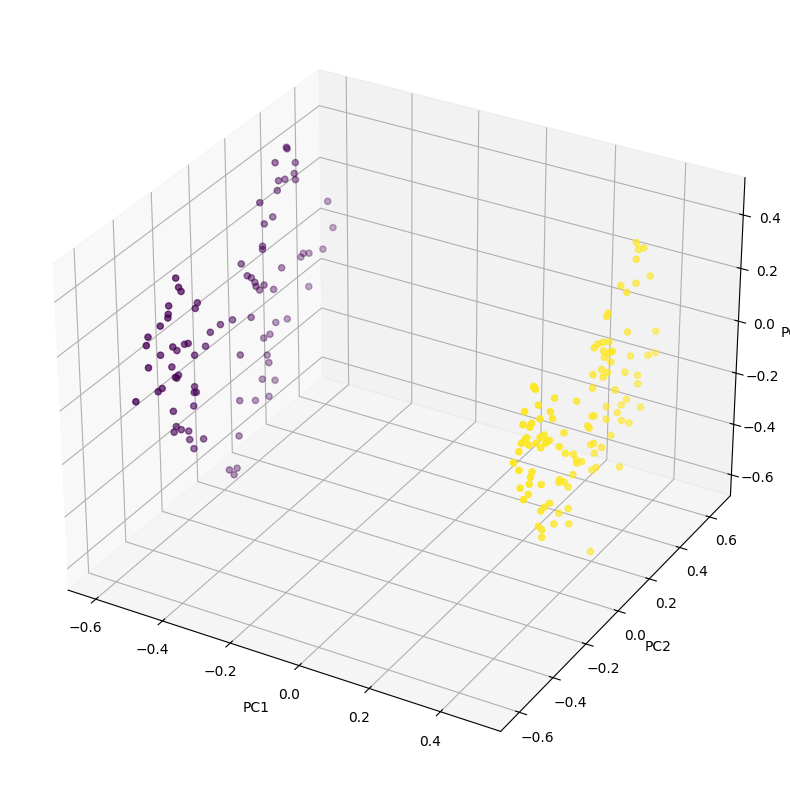

In [30]:
# Membuat visualisasi dari sebaran data dengan pertimbangan principle component
# dalam ruang 3 dimensi dan hasil clustering dengan K-Means
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(data_pca['PC1'], data_pca['PC2'], data_pca['PC3'], c=kmeans.fit_predict(X))
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
plt.show()

Penjelasan:

titik digambar pada koordinat PC1, PC2, PC3 dan diwarnai sesuai label K-Means. Dua kelompok terpisah jelas sepanjang PC1, wajar karena PC1 hampir sama dengan
Gender. Pada PC2 dan PC3 kedua warna tercampur.

## **3. Clustering dengan Agglomerative dan Davies-Bouldin Index**


Hasil Pencarian Nilai Cluster Terbaik :



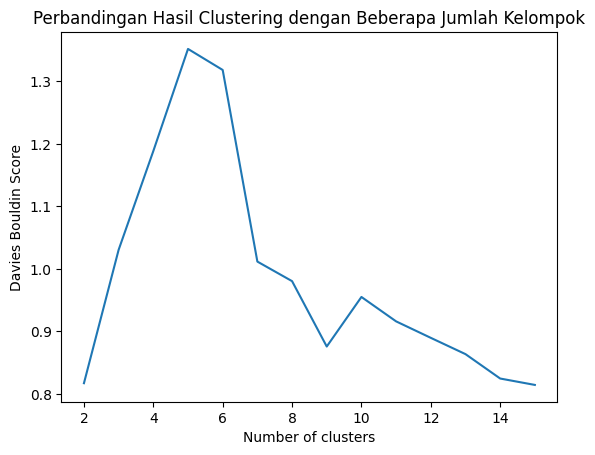

In [31]:
# Proses clustering dengan menggunakan Agglomerative yang mempertimbangkan beberapa
# nilai/jumlah kelompok
list_daviesBouldinScore = []
for i in range(2, 16):
  aggloClustering = AgglomerativeClustering(n_clusters=i, linkage='complete')
  aggloClustering.fit(X)
  list_daviesBouldinScore.append(davies_bouldin_score(X, aggloClustering.fit_predict(X)))
print ("Hasil Pencarian Nilai Cluster Terbaik :\n")
plt.plot(range(2, 16), list_daviesBouldinScore)
plt.title('Perbandingan Hasil Clustering dengan Beberapa Jumlah Kelompok')
plt.xlabel('Number of clusters')
plt.ylabel('Davies Bouldin Score')
plt.show()

Penjelasan:

Agglomerative bekerja dari bawah ke atas. Tiap titik mulai sebagai cluster sendiri, lalu dua cluster terdekat digabung berulang kali. linkage='complete' mengukur jarak antar cluster dari pasangan titik yang paling jauh, sehingga cluster cenderung padat. Dicoba k = 2 sampai 15 dengan Davies-Bouldin Index (makin kecil makin baik).

Hasilnya DBI di k=2 sekitar 0.82, naik sampai puncaknya sekitar 1.35 di k=5, lalu turun lagi. Nilai terendah ada di k=15 (sekitar 0.81), tapi selisihnya dengan k=2 sangat kecil.

In [32]:
# Penggunaan model clustering dengan nilai cluster yang dianggap terbaik
aggloClustering = AgglomerativeClustering(n_clusters=2, linkage='complete')
aggloClustering.fit(X)
print(aggloClustering.fit_predict(X))

[0 0 1 1 1 1 1 1 0 1 0 1 1 1 0 0 1 0 0 1 0 0 1 0 1 0 1 0 1 1 0 1 0 0 1 1 1
 1 1 1 1 0 0 1 1 1 1 1 1 1 1 0 1 0 1 0 1 0 1 0 0 0 1 1 0 0 1 1 0 1 0 1 1 1
 0 0 1 0 1 1 0 0 0 1 1 0 1 1 1 1 1 0 0 1 1 0 1 1 0 0 1 1 0 0 0 1 1 0 0 0 0
 1 1 0 1 1 1 1 1 1 0 1 1 0 1 1 0 0 0 0 0 0 1 1 0 1 1 0 0 1 1 0 1 1 0 0 0 1
 1 0 0 0 1 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 1 0 0 0 0 0 1 1 0 0 0 0 1 1 0 1 1
 0 1 0 1 1 1 1 0 1 1 1 1 0 0 0]


Penjelasan:

Dipakai n_clusters=2. Berbeda dengan K-Means, Agglomerative tidak punya
centroid awal maupun random_state, jadi hasilnya selalu sama. Ukuran clusternya 88 dan 112, dan pembagiannya sama dengan hasil K-Means.

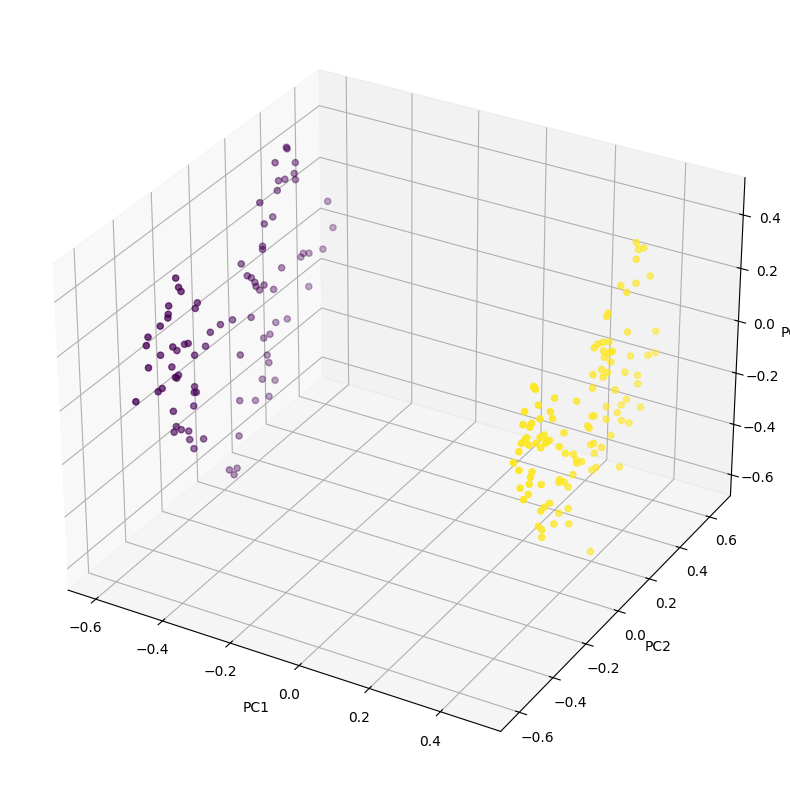

In [33]:
# Membuat visualisasi dari sebaran data dengan pertimbangan principle component
# dalam ruang 3 dimensi dan hasil clustering dengan Agglomerative
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(data_pca['PC1'], data_pca['PC2'], data_pca['PC3'], c=aggloClustering.fit_predict(X))
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
plt.show()

Penjelasan: plotnya sama dengan hasil K-Means karena anggota kedua cluster identik.